# Supplementary Fig. 5c: decoding performance of the CEBRA model, spontaneous regime

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel c of Supplementary Fig. 5: precision and recall of a model that uses both the full spike waveforms and the quality metrics to curate the 'good' units (agreement score of at least 0.8 with a ground truth neuron) amongst the single-units sorted by Kilosort4 from the biophysical simulation of the spontaneous regime. Each black dot is one cross-validated fold, orange dots are the medians over 100 folds. The red dashed line marks 0.5. Source data and svg are saved in figures/8_source_data/supp_fig5c/.

**prerequisites**: the `spikebias` environment with `cebra==0.4.0` and `scikit-learn==1.5.2` (the versions pinned in `envs/cebraspike.txt`; cebra 0.4.0 does not work with scikit-learn 1.6 and later) and `literate-dataclasses`; a GPU makes the training faster (about 6 minutes for 100 folds on an RTX 5090).

**method (as in the paper's notebook supp_fig5_C_curation_cebraspike_NS.ipynb)**
* dataset: the sorted single-units (first 10 minutes) with at least 25 spikes; for each unit the 25 first spike waveforms (+/- 3 ms around the peak, on the site with the largest amplitude) are concatenated into one vector of 6,000 values, to which the 11 quality metrics of the unit are appended (`src/nodes/models/CebraSpike/dataloader.py`); units with missing metrics are dropped; label: 'good' (spike assignment bias containing 'good') or degraded ('merged + partial')
* quality metrics are computed on the first 10 minutes of the recording (the waveform extractor of the single-units is the one made by fig5e.ipynb)
* model: CEBRA (offset10-model, 3 output dimensions, cosine distance, supervised by the good/degraded label, 40 iterations, learning rate 0.001, batch size = number of columns of the dataset as in the paper's notebook) followed by a 20-nearest-neighbor classifier on the embeddings
* evaluation: 100 random splits (80% of the units of each class for training, 20% for testing; stratified), precision and recall on the test units

In [1]:
# SETUP PACKAGES
import os
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from matplotlib import pyplot as plt
warnings.simplefilter(action="ignore")

# SET PROJECT PATH
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(PROJ_PATH)
from src.nodes.models.CebraSpike import dataloader as cs_dataloader
from src.nodes.models.CebraSpike.models import CebraSpike

# DATA: 10 minutes of the spontaneous regime sorted with Kilosort4
QUALITY_PATH = "dataset/01_intermediate/quality/sorting_quality.csv"
SORTING_PATH = "dataset/01_intermediate/sorting/npx_spont/SortingKS4_10m"
GROUND_TRUTH_PATH = "dataset/00_raw/ground_truth_npx_spont_10m"
WAVEFORMS_PATH = "dataset/01_intermediate/waveforms/npx_spont/SortingKS4_10m_single_units"      # waveforms of the sorted single-units (first 10 minutes, see fig5e.ipynb)
EXP, SORTER = "NS", "KS4"
MODEL_PATH = "models/cebra/spont_40_iterations/"     # weights of the 100 cross-validated models (.pt) and folds.csv

# MODEL PARAMETERS
N_SPIKES = 25               # spikes per unit
INTERVAL_MS = 3             # waveform window: +/- 3 ms around the spike peak (240 samples at 40 kHz)
N_NEIGHBORS = 20            # k-nearest neighbor decoder
SEEDS = np.arange(0, 100, 1)

# FIGURE SETTINGS
plt.rcParams["font.family"] = "DejaVu Sans"   # the paper's figure was drawn without Arial (matplotlib default font)
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
savefig_cfg = {"transparent": True, "dpi": 300}

## Load the dataset

In [2]:
%%time

data_cs = cs_dataloader.load_dataset(qpath=QUALITY_PATH, sorting_path=SORTING_PATH, sortingtrue_path=GROUND_TRUTH_PATH, study_path=WAVEFORMS_PATH, study_singleu_path=WAVEFORMS_PATH,
                                     exp=EXP, sorter=SORTER, n_site=384, num_spikes=N_SPIKES, interval_ms=INTERVAL_MS, downsampling=1, load_we_if_exists=True, load_amp_if_exists=True, load_qmetrics_if_exists=False)
dataset = data_cs["dataset"]
print("units:", dataset["data"].shape[0], "| good:", int(dataset["label"].sum()), "| features:", dataset["data"].shape[1])

2026-11-03 09:20:38,737 - root - dataloader.py - load_dataset - INFO - Starting loading dataset..


2026-11-03 09:20:38,738 - root - dataloader.py - load_dataset - INFO - Computing sorted unit quality metrics..


  0%|          | 0/184 [00:00<?, ?it/s]

****************** Analysing data completion ***************
quality metrics are: Index(['amplitude_cutoff', 'firing_range', 'firing_rate',
       'isi_violations_ratio', 'presence_ratio', 'rp_contamination',
       'rp_violations', 'sd_ratio', 'snr', 'silhouette', 'mad_ratio'],
      dtype='object')
Data completion: amplitude_cutoff        184
firing_range            184
firing_rate             184
isi_violations_ratio    184
presence_ratio          184
rp_contamination        184
rp_violations           184
sd_ratio                184
snr                     184
silhouette              182
mad_ratio               184
dtype: int64
Dropping units with missing metrics...
nb of units before curation: 184
nb of units after curation: 182
2026-11-03 09:20:55,228 - root - dataloader.py - load_dataset - INFO - Computed quality metrics


Recording sampling frequency: 40000.0


ex. dataset shape (L4): (26, 6000)
ex. label shape (L4): (26,)

unit sample size:

L1:  1 units
L23:  2 units
L4:  26 units
L5:  116 units
L6:  39 units

********** DATASET STATS **********:


unit count:

l1: 0
l23: 1
l4: 26
l5: 116
l6: 39
units: 182 | good: 84 | features: 6011
CPU times: user 12.9 s, sys: 4.19 s, total: 17.1 s
Wall time: 18.1 s


## Train and evaluate the CEBRA model (6 minutes)

In [3]:
%%time

torch.manual_seed(0)       # reproducibility
csmodel = CebraSpike(cfg={
    "model_architecture": "offset10-model",   # receptive field of size 10
    "distance": "cosine",                     # adapted to contrastive learning
    "batch_size": dataset["data"].shape[1],
    "temperature_mode": "auto",
    "learning_rate": 0.001,
    "max_iterations": 40,
    "conditional": "time_delta",
    "time_offsets": 10,
    "output_dimension": 3,
    "device": "cuda_if_available",
    "verbose": False})
os.makedirs(MODEL_PATH, exist_ok=True)
results = csmodel.evaluate(dataset, MODEL_PATH, is_train=True, seeds=SEEDS, n_neighbors=N_NEIGHBORS)
stats_ = results["metric_stats"]
print(f"precision median {stats_['precision_median']:.3f} (95% CI {stats_['precision_ci95']:.3f}), recall median {stats_['recall_median']:.3f} (95% CI {stats_['recall_ci95']:.3f})")

precision median 0.607 (95% CI 0.025), recall median 0.824 (95% CI 0.029)
CPU times: user 5min 18s, sys: 483 ms, total: 5min 18s
Wall time: 5min 14s


## Source data: precision and recall of each fold

In [4]:
df = pd.DataFrame({"fold": SEEDS, "precision": [m["precision"] for m in results["metric_data"]], "recall": [m["recall"] for m in results["metric_data"]]})
display(df[["precision", "recall"]].agg(["median", "count"]))

,precision,recall
median,0.607143,0.823529
count,100.000000,100.000000


## Plot, same as the paper's panel c

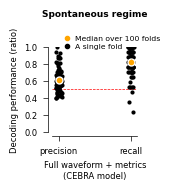

In [5]:
def plot_source_data(df: pd.DataFrame, title="Spontaneous regime"):
    """Precision and recall of the model on the test units of each cross-validated fold (black dots); median and 95% CI over folds (orange); red dashed line: 0.5"""

    np.random.seed(0)     # the horizontal jitter of the dots is random: fix it so that every plot is identical
    fig, ax = plt.subplots(1, 1, figsize=(1.1, 1.1))
    sns.stripplot(ax=ax, data=df[["precision", "recall"]], jitter=0.04, color="k", size=3)
    for x, col in enumerate(["precision", "recall"]):
        ax.errorbar(x=x, y=np.nanmedian(df[col]), yerr=1.96 * np.std(df[col]) / np.sqrt(len(df[col])), marker="o", color="orange", markeredgecolor="w", markersize=5, zorder=np.inf)
    ax.axhline(0.5, color="r", linestyle="--", linewidth=0.5, zorder=0)

    # disconnect axes (R style)
    ax.spines[["right", "top"]].set_visible(False)
    ax.spines["bottom"].set_position(("axes", -0.05))
    ax.yaxis.set_ticks_position("left")
    ax.spines["left"].set_position(("axes", -0.05))
    ax.set_ylim([0, 1])
    ax.set_yticks(np.arange(0, 1.1, 0.2), [f"{v:.1f}" for v in np.arange(0, 1.1, 0.2)])
    ax.set_ylabel("Decoding performance (ratio)")
    ax.set_xlabel("Full waveform + metrics\n(CEBRA model)")
    ax.set_title(title, fontweight="bold", fontsize=6.5, pad=22)

    # legend
    ax.plot([], [], "o", color="orange", markersize=3, label="Median over 100 folds")
    ax.plot([], [], "o", color="k", markersize=3, label="A single fold")
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0.0, 1.22), handletextpad=0.1, labelspacing=0.2, fontsize=5.5)
    return fig, ax


fig, ax = plot_source_data(df)

## Save the figure and the source data

In [6]:
os.makedirs("figures/8_source_data/supp_fig5c", exist_ok=True)
plt.savefig("figures/8_source_data/supp_fig5c/supp_fig5c.svg", bbox_inches="tight", **savefig_cfg)
df.to_excel("figures/8_source_data/supp_fig5c/supp_fig5c.xlsx", index=False)

<Figure size 640x480 with 0 Axes>

## Check: replot from the saved source data

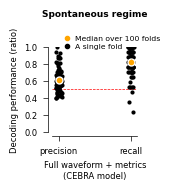

In [7]:
df_loaded = pd.read_excel("figures/8_source_data/supp_fig5c/supp_fig5c.xlsx")
fig, ax = plot_source_data(df_loaded)